# Stage 5 — Monte Carlo Baseline and Tabular Q-Learning (v5)

## 1. Stage 5 overview and objective
**Objective.** Find plausible market-factor shock sequences that breach the portfolio's 5-day risk limit, and improve Q-learning's ability to find *more plausible* breaches without losing breach reliability. Implausible breaches never count as stress scenarios.

**Methods.** Monte Carlo random search is the baseline; tabular Q-learning is the method being improved. The scripted moderate decline is a reference, not a learned method. PPO is a historical reference (saved results, not re-run). CEM was evaluated in v1–v3 and is **not** part of this comparison (its results remain in `backups/stage_5_full_run_v{1,2,3}_2026-10-24.ipynb`).

**Experiments in this notebook.**
- **Experiment 0 — exhaustive diagnostic.** All $9^5=59{,}049$ fixed five-day sequences of Q-learning's nine actions, evaluated deterministically. This is a search-space diagnostic (the best fixed sequence the action set allows), **not an RL result**.
- **Experiment 1 — plausibility-margin reward.** Q-learning with an optional bonus on valid breaches only: $m=\ln(\rho_t/q)/\ln(1/q)$ clamped to $[0,1]$ ($m=0$ for $\rho_t\le q$), reward $+\beta m$ on the transition where the environment pays the valid-breach reward. Arms $\beta\in\{0,5\}$ × training seeds {43, 44, 45}, 20,000 episodes each, everything else unchanged. $\beta=0$ is the v3 Q-learning; $\beta=5$ was fixed in advance (the value at which the expected bonus of the scripted path's plausibility offsets Q-learning's reliability advantage) and is **not tuned on these results**.

- **Experiment 2 — learning benchmarks (v5).** (a) a certainty-equivalent dynamic-programming (DP) policy, fitted by backward induction on an empirical model of the same discretised MDP; (b) Double Q-learning; (c) 5-step (full-return) targets. All use the β = 5 reward, the same state, actions, seeds and evaluation, to show whether tabular Q-learning is under-learning or whether the state/action design is the limit.
- **Scenario diversity (v5).** A candidate-level analysis of *which kinds* of plausible breaches the methods find: transparent factor-path families, a scale-free distance, threshold-sensitive clustering, robustness on fresh residual draws and a scenario library. The v4 outputs are preserved inside this notebook's metadata (`preserved_runs`); the v4 cells are unchanged and re-run with the same seeds.

**Decision rule (set before running).** $\beta=5$ counts as an improvement only if, for the adaptive policy, the median valid-breach rank is higher than for $\beta=0$, the valid-breach rate stays at least 80%, and the gain holds for each of the three seeds.

**Execution.** `RUN_MODE = "smoke"` runs tiny budgets (labelled **SMOKE TEST — NOT YET EVALUATED**); `"full"` is the authorised experiment. The 2024–2025 test split is never used.

## 2. Imports, configuration, and reproducibility

In [1]:
import dataclasses
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

from rlstress.config import PROJECT_ROOT, load_config, resolve_path
from rlstress.data.storage import read_frame
from rlstress.rl.evaluation import evaluate_policy, summarize
from rlstress.rl.policies import RandomPolicy, scripted_decline_policy, zero_policy
from rlstress.rl.training import build_env
from rlstress.search import (GroupedActions, OpenLoopPolicy, QConfig, QGreedyPolicy, StateEncoder, best_so_far,
                             enumerate_sequences, episode_metrics, evaluate_path, monte_carlo, monte_carlo_sequences,
                             plausibility_margin, sort_key, train_q_learning)
from rlstress.shocks import ShockModel, fit_shock_model

%matplotlib inline
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3dc", "grid.linewidth": 0.8})

CFG = load_config()                                   # config/default.toml, unchanged
SIM, ENVC, TRN = CFG.simulation, CFG.environment, CFG.training
Q_THRESHOLD = SIM.min_plausibility                    # q = 0.01
H, K = SIM.horizon_days, len(SIM.factors)
SEED = SIM.seed
RETURNS_PATH = resolve_path(CFG.risk.returns_path, PROJECT_ROOT)
STAGE4_MODEL = PROJECT_ROOT / SIM.output_dir / "shock_model.json"
PPO_MAIN = PROJECT_ROOT / TRN.output_dir / "run_20261019T071324Z_main"
V3_FULL_RUN = PROJECT_ROOT / "backups" / "stage_5_full_run_v3_2026-10-24.ipynb"

RUN_MODE = "full"   # "smoke": tiny bounded mechanics check. "full": separately authorised experiment.
SETTINGS = {
    "smoke": dict(mc_budget=120, enum_multipliers=(-2.0, 0.0), q_episodes=200, mcd_draws=4, report_episodes=40,
                  dp_episodes=300, variant_episodes=200, selection_episodes=20, top_enum=100),
    "full":  dict(mc_budget=6000, enum_multipliers=(-2.0, -1.0, 0.0), q_episodes=20_000, mcd_draws=10, report_episodes=TRN.validation_episodes,
                  dp_episodes=20_000, variant_episodes=20_000, selection_episodes=TRN.selection_episodes, top_enum=500),
}[RUN_MODE]
BETAS, Q_SEEDS = (0.0, 5.0), (SEED + 1, SEED + 2, SEED + 3)            # 43, 44, 45; beta fixed before running
P_VALID_TARGET = 0.80                                                    # decision-rule floor (proposed criterion)
REPORT_SEEDS = range(TRN.eval_seed_sets[0], TRN.eval_seed_sets[0] + SETTINGS["report_episodes"])   # validation anchors, common to every arm
MCD_DRAW_SEED, MCD_SEED = 50_000, SEED + 4                               # discrete Monte Carlo: training anchors, its own seeds
DP_SEED = 60_000                                                         # DP model data: training anchors, its own seeds
SELECTION_SEEDS = range(TRN.selection_seed, TRN.selection_seed + SETTINGS["selection_episodes"])   # validation anchors, screening only
V4_RECORDED = {"enum_best_rank": 0.0859, "q_beta5_seed43_adaptive_median_rank": 0.0415, "q_beta5_seed43_adaptive_valid": 1.0,
               "q_beta0_seed43_steps": 79_738, "mcd_reporting_valid": 0.746}   # from the preserved v4 outputs
BANNER = ("SMOKE TEST (tiny budget) — mechanics check only; results NOT YET EVALUATED" if RUN_MODE == "smoke"
          else "FULL RUN v4 — authorised experiment")

missing = [str(p) for p in (RETURNS_PATH, STAGE4_MODEL, PPO_MAIN / "summary.json") if not p.exists()]
assert not missing, f"required files missing: {missing}"
assert not set(REPORT_SEEDS) & set(range(MCD_DRAW_SEED, MCD_DRAW_SEED + SETTINGS["mcd_draws"]))
assert not set(REPORT_SEEDS) & set(SELECTION_SEEDS), "screening and reporting episodes must differ"
print(f"RUN_MODE = {RUN_MODE}: {BANNER}")
print(f"Settings: {SETTINGS} | betas {BETAS} | Q seeds {Q_SEEDS} | reporting seeds {REPORT_SEEDS.start}-{REPORT_SEEDS.stop - 1}")

RUN_MODE = full: FULL RUN v4 — authorised experiment
Settings: {'mc_budget': 6000, 'enum_multipliers': (-2.0, -1.0, 0.0), 'q_episodes': 20000, 'mcd_draws': 10, 'report_episodes': 500, 'dp_episodes': 20000, 'variant_episodes': 20000, 'selection_episodes': 200, 'top_enum': 500} | betas (0.0, 5.0) | Q seeds (43, 44, 45) | reporting seeds 20000-20499


## 3. Existing Stage 4 environment verification

In [2]:
source = read_frame(RETURNS_PATH)
model = ShockModel.from_dict(json.loads(STAGE4_MODEL.read_text()))
train_start, train_end = CFG.data.splits.as_dict()["train"]
refit = fit_shock_model(source, CFG.portfolio.tickers, SIM, train_start, train_end, CFG.portfolio.return_column_template)
same_model = (np.array_equal(refit.sigma, model.sigma) and np.array_equal(refit.raw_loadings, model.raw_loadings)
              and refit.nu == model.nu and refit.path_calibration == model.path_calibration)
assert same_model, "saved Stage 4 model differs from a training-split refit"

cfg_mean = dataclasses.replace(CFG, simulation=dataclasses.replace(SIM, residual_mode="mean"))
search_env = build_env(cfg_mean, source, model, Q_THRESHOLD, "train")        # deterministic, training anchors
train_env = build_env(CFG, source, model, Q_THRESHOLD, "train")              # sampled residuals, training anchors
eval_env = build_env(CFG, source, model, Q_THRESHOLD, "validation")          # sampled residuals, validation anchors
SEARCH_ANCHOR = search_env.market_states.index[len(search_env.market_states) // 2]
OBS = {n: i for i, n in enumerate(search_env.observation_names)}
evaluate = lambda x: evaluate_path(search_env, x, SEARCH_ANCHOR, SEED)
probe = np.tile(np.full(K, -0.2), (H, 1))
outcomes = {str(a.date()): evaluate_path(search_env, probe, a, SEED)["values"] for a in search_env.market_states.index[[0, len(search_env.market_states) // 2, -1]]}
assert len({tuple(v) for v in outcomes.values()}) == 1, "outcome depends on the anchor date"
display(pd.DataFrame({"item": ["saved model == training refit", "fit window", "factor bounds |a| = 1", "deterministic env", "training env", "evaluation env",
                               "anchor dependence of outcomes", "reward weights (unchanged)"],
                      "value": [same_model, f"{model.fit_start} -> {model.fit_end}",
                                ", ".join(f"{f.removesuffix('_return')} ±{b:.2%}" for f, b in zip(model.factors, search_env.simulator.bounds)),
                                "residual_mode=mean, train anchors", "residual_mode=sample, train anchors",
                                f"residual_mode=sample, validation anchors {eval_env.market_states.index.min().date()} -> {eval_env.market_states.index.max().date()}",
                                "none (dynamics ignore the anchor: 'validation episodes' differ only in residual draws)",
                                str(dataclasses.asdict(ENVC))]}).style.hide(axis="index"))

item,value
saved model == training refit,True
fit window,2015-01-05 -> 2021-12-31
factor bounds |a| = 1,"SPY ±12.67%, QQQ ±15.96%, XLF ±16.92%, XLE ±23.36%"
deterministic env,"residual_mode=mean, train anchors"
training env,"residual_mode=sample, train anchors"
evaluation env,"residual_mode=sample, validation anchors 2022-01-03 -> 2023-12-29"
anchor dependence of outcomes,none (dynamics ignore the anchor: 'validation episodes' differ only in residual draws)
reward weights (unchanged),"{'breach_reward': 10.0, 'severity_weight': 5.0, 'plausibility_penalty': 0.2, 'magnitude_penalty': 0.5, 'step_penalty': 0.01, 'invalid_penalty': 5.0, 'implausible_breach_penalty': 0.0, 'implausible_breach_credit': 0.0, 'terminate_on_breach': True}"


## 4. Risk-limit and plausibility verification, saved references

In [3]:
display(pd.DataFrame([{"limit": l.name, "metric": l.metric, "horizon_days": l.horizon_days, "threshold": l.threshold, "rule": l.breach_rule,
                       "used by environment": l in search_env.path_limits} for l in CFG.risk.limits]).style.hide(axis="index").format({"threshold": "{:.0%}"}))

def ppo_across_seeds(run_dir, q):
    c = pd.DataFrame(json.loads((run_dir / "summary.json").read_text())["comparison"])
    c = c[(c["threshold"] == q) & c["policy"].str.startswith("ppo_seed_")]
    out = {k: c[f"{k}_mean"].mean() for k in ("valid_breach_rate", "breach_rate", "implausible_breach_rate", "episode_return_mean")}
    out.update(valid_breach_rate_std=c["valid_breach_rate_mean"].std(ddof=1), n_seeds=len(c), n_episodes=int(c["n_episodes"].sum()))
    return out
ppo_ref = ppo_across_seeds(PPO_MAIN, Q_THRESHOLD)
print(f"PPO (saved reference, q = {Q_THRESHOLD}): valid {ppo_ref['valid_breach_rate']:.1%} ± {ppo_ref['valid_breach_rate_std']:.1%} over {ppo_ref['n_seeds']} seeds; "
      f"implausible {ppo_ref['implausible_breach_rate']:.1%}")
print(f"v3 baseline notebook preserved: {V3_FULL_RUN.exists()} ({V3_FULL_RUN.relative_to(PROJECT_ROOT)})")
print("Margin m = ln(rank/q)/ln(1/q):", {r: round(plausibility_margin(r, Q_THRESHOLD), 3) for r in (0.01, 0.0205, 0.0808, 0.2014, 1.0)})

limit,metric,horizon_days,threshold,rule,used by environment
stress_loss_5d,cumulative_loss,5,10%,>=,True
stress_drawdown_5d,max_drawdown,5,10%,>=,True
historical_var_95_1d,historical_var,1,3%,>=,False
historical_cvar_95_1d,historical_cvar,1,6%,>=,False


PPO (saved reference, q = 0.01): valid 14.8% ± 12.1% over 3 seeds; implausible 85.2%
v3 baseline notebook preserved: True (backups/stage_5_full_run_v3_2026-10-24.ipynb)
Margin m = ln(rank/q)/ln(1/q): {0.01: 0.0, 0.0205: 0.156, 0.0808: 0.454, 0.2014: 0.652, 1.0: 1.0}


## 5. Reference scenarios: no shock and scripted decline

In [4]:
def summary_row(name, rec):
    return {"scenario": name, "days executed": rec["days"], "breached": rec["breached"], "VALID": rec["valid"], "rank rho_t": rec["rank"],
            "margin m": plausibility_margin(rec["rank"], Q_THRESHOLD) if rec["valid"] else 0.0, "S_t": rec["S"], "drawdown": rec["drawdown"],
            "mean a^2 (executed)": rec["mean_sq_action"], "env return": rec["return"]}
FMT = {"rank rho_t": "{:.4f}", "margin m": "{:.3f}", "S_t": "{:.2f}", "drawdown": "{:.2%}", "mean a^2 (executed)": "{:.4f}", "env return": "{:+.2f}"}
ZERO_PATH, SCRIPTED_PATH = np.zeros((H, K)), np.full((H, K), TRN.scripted_action)
zero_rec, scripted_rec = evaluate(ZERO_PATH), evaluate(SCRIPTED_PATH)
display(pd.DataFrame([summary_row("no shock", zero_rec), summary_row("scripted decline (reference)", scripted_rec)]).set_index("scenario").style.format(FMT))

,days executed,breached,VALID,rank rho_t,margin m,S_t,drawdown,mean a^2 (executed),env return
scenario,,,,,,,,,
no shock,5,False,False,1.0000,0.000,0.00,0.00%,0.0000,-0.05
scripted decline (reference),5,True,True,0.0808,0.454,8.89,11.03%,0.0225,+8.67


## 6. Monte Carlo baseline (original, unchanged)
Uniform paths on $[-1,1]^{20}$, deterministic evaluation, 6,000 candidates, seed 44 — exactly the v1–v3 baseline.

In [5]:
t0 = time.perf_counter()
mc = monte_carlo(evaluate, H * K, SETTINGS["mc_budget"], seed=SEED + 2)
mc_runtime = time.perf_counter() - t0
mc_recs, mc_best = mc["records"], mc["best"]
print(BANNER)
print(f"Monte Carlo (original): {len(mc_recs)} candidates, {sum(r['days'] for r in mc_recs)} steps, {mc_runtime:.1f}s | breaching {sum(r['breached'] for r in mc_recs)} | "
      f"valid {sum(r['valid'] for r in mc_recs)} | best {'VALID' if mc_best['valid'] else 'NOT valid'}: rank {mc_best['rank']:.4f}, drawdown {mc_best['drawdown']:.2%}")

FULL RUN v4 — authorised experiment
Monte Carlo (original): 6000 candidates, 26901 steps, 62.4s | breaching 2027 | valid 0 | best NOT valid: rank 0.0011, drawdown 10.68%


## 7. Q-Learning state and action discretisation (unchanged from v3)
Nine actions: equity group (SPY, QQQ) and sector group (XLF, XLE), each at $\{-0.30,-0.15,0\}$ in Stage 4 action units. 120 states: day × drawdown bin × rank bin. The state is not Markov.

In [6]:
ACTS = GroupedActions(abs(TRN.scripted_action), k=K)
ENC = StateEncoder(OBS, H, dd_edges=[0.02, 0.04, 0.06, 0.08, 0.10], rank_edges=[Q_THRESHOLD, 0.05, 0.20])
names = [f.removesuffix("_return") for f in model.factors]
display(pd.DataFrame({"index": range(len(ACTS)), "action": [ACTS.label(i, names) for i in range(len(ACTS))]}).style.hide(axis="index"))
print(f"{len(ACTS)} actions x {int(np.prod(ENC.shape))} states = {len(ACTS) * int(np.prod(ENC.shape))} state-action pairs")

index,action
0,"SPY/QQQ -0.30, XLF/XLE -0.30"
1,"SPY/QQQ -0.30, XLF/XLE -0.15"
2,"SPY/QQQ -0.30, XLF/XLE +0.00"
3,"SPY/QQQ -0.15, XLF/XLE -0.30"
4,"SPY/QQQ -0.15, XLF/XLE -0.15"
5,"SPY/QQQ -0.15, XLF/XLE +0.00"
6,"SPY/QQQ +0.00, XLF/XLE -0.30"
7,"SPY/QQQ +0.00, XLF/XLE -0.15"
8,"SPY/QQQ +0.00, XLF/XLE +0.00"


9 actions x 120 states = 1080 state-action pairs


## 8. Experiment 0 — exhaustive enumeration of the nine-action space (deterministic diagnostic, not RL)
Every fixed five-day sequence is evaluated by the deterministic environment. Sequences sharing the executed prefix of an early-terminating sequence have identical outcomes and reuse it (`simulations` counts actual simulator runs).

In [7]:
enum_acts = GroupedActions(abs(TRN.scripted_action), k=K, multipliers=SETTINGS["enum_multipliers"])
t0 = time.perf_counter()
enum_df = enumerate_sequences(evaluate, enum_acts, H)
enum_runtime = time.perf_counter() - t0
expected = len(enum_acts) ** H
assert len(enum_df) == expected and enum_df["sequence"].nunique() == expected
assert all(np.abs(enum_acts.actions[list(s)]).max() <= 1.0 for s in enum_df["sequence"])
valid_enum = enum_df[enum_df["valid"]]
enum_best = valid_enum.sort_values(["rank", "log_tail"], ascending=False).iloc[0] if len(valid_enum) else None
print(BANNER, "| DETERMINISTIC SEARCH-SPACE DIAGNOSTIC, NOT AN RL RESULT")
print(f"Enumerated {len(enum_df):,} sequences ({len(enum_acts)} actions ^ {H}) with {enum_df.attrs['simulations']:,} simulator runs in {enum_runtime:.1f}s")
cats = pd.DataFrame({"category": ["valid breach", "implausible breach", "no breach"],
                     "sequences": [int(enum_df["valid"].sum()), int(enum_df["implausible"].sum()), int((~enum_df["breached"]).sum())],
                     "best rank in category": [enum_df.loc[enum_df["valid"], "rank"].max(), enum_df.loc[enum_df["implausible"], "rank"].max(),
                                               enum_df.loc[~enum_df["breached"], "rank"].max()]})
display(cats.style.hide(axis="index").format({"best rank in category": "{:.4f}"}, na_rep="—"))
if enum_best is not None:
    top = valid_enum.sort_values(["rank", "log_tail"], ascending=False).head(5).copy()
    top["executed actions"] = [" | ".join(enum_acts.label(i, names) for i in s[:d]) for s, d in zip(top["sequence"], top["days"])]
    display(top[["executed actions", "days", "rank", "drawdown", "mean_sq_action"]].style.hide(axis="index")
            .format({"rank": "{:.4f}", "drawdown": "{:.2%}", "mean_sq_action": "{:.4f}"}).set_caption("Top 5 valid fixed sequences (deterministic)"))
ENUM_BEST_PATH = enum_acts.actions[list(enum_best["sequence"])] if enum_best is not None else None

FULL RUN v4 — authorised experiment | DETERMINISTIC SEARCH-SPACE DIAGNOSTIC, NOT AN RL RESULT
Enumerated 59,049 sequences (9 actions ^ 5) with 40,137 simulator runs in 470.7s


category,sequences,best rank in category
valid breach,19796,0.0859
implausible breach,17803,0.0097
no breach,21450,1.0000


executed actions,days,rank,drawdown,mean_sq_action
"SPY/QQQ -0.30, XLF/XLE -0.15 | SPY/QQQ -0.15, XLF/XLE -0.15 | SPY/QQQ -0.15, XLF/XLE -0.15 | SPY/QQQ +0.00, XLF/XLE +0.00 | SPY/QQQ -0.15, XLF/XLE -0.15",5,0.0859,10.44%,0.0248
"SPY/QQQ -0.30, XLF/XLE -0.15 | SPY/QQQ -0.15, XLF/XLE -0.15 | SPY/QQQ +0.00, XLF/XLE +0.00 | SPY/QQQ -0.15, XLF/XLE -0.15 | SPY/QQQ -0.15, XLF/XLE -0.15",5,0.0859,10.44%,0.0248
"SPY/QQQ -0.30, XLF/XLE -0.15 | SPY/QQQ +0.00, XLF/XLE +0.00 | SPY/QQQ -0.15, XLF/XLE -0.15 | SPY/QQQ -0.15, XLF/XLE -0.15 | SPY/QQQ -0.15, XLF/XLE -0.15",5,0.0859,10.44%,0.0248
"SPY/QQQ -0.15, XLF/XLE -0.15 | SPY/QQQ -0.30, XLF/XLE -0.15 | SPY/QQQ -0.15, XLF/XLE -0.15 | SPY/QQQ +0.00, XLF/XLE +0.00 | SPY/QQQ -0.15, XLF/XLE -0.15",5,0.0859,10.44%,0.0248
"SPY/QQQ -0.15, XLF/XLE -0.15 | SPY/QQQ -0.30, XLF/XLE -0.15 | SPY/QQQ +0.00, XLF/XLE +0.00 | SPY/QQQ -0.15, XLF/XLE -0.15 | SPY/QQQ -0.15, XLF/XLE -0.15",5,0.0859,10.44%,0.0248


## 9. Experiment 1 — Q-learning with and without the plausibility-margin bonus
Training: sampled residuals, training anchors, 20,000 episodes per run, ε 1→0.05 over 80% of episodes with a visit-count bonus, $\alpha=\max(0.05,1/n)$, $\gamma$ = `training.gamma`, zero initial values, greedy over visited actions. Only `margin_bonus` (β) differs between arms; each seed is the training RNG seed and the episode-seed offset. Training statistics below are **exploratory** (ε-greedy) and are not policy performance.

In [8]:
runs = {}
for beta in BETAS:
    for seed in Q_SEEDS:
        t0 = time.perf_counter()
        agent, log = train_q_learning(train_env, ENC, ACTS, QConfig(episodes=SETTINGS["q_episodes"], gamma=TRN.gamma, margin_bonus=beta), seed=seed)
        runs[(beta, seed)] = {"agent": agent, "log": log, "runtime": time.perf_counter() - t0}
tail = max(1, SETTINGS["q_episodes"] // 10)
train_table = pd.DataFrame([{"beta": b, "seed": s, "episodes": len(r["log"]), "env steps": int(r["log"]["steps"].sum()), "runtime s": r["runtime"],
                             "pairs visited": int((r["agent"].N > 0).sum()), "valid (all, exploratory)": r["log"]["valid"].mean(),
                             f"valid (last {tail})": r["log"]["valid"].tail(tail).mean(), "mean bonus per valid episode":
                             r["log"].loc[r["log"]["valid"], "margin_bonus"].mean() if r["log"]["valid"].any() else np.nan}
                            for (b, s), r in runs.items()])
print(BANNER)
display(train_table.style.hide(axis="index").format({"runtime s": "{:.1f}", "valid (all, exploratory)": "{:.1%}", f"valid (last {tail})": "{:.1%}",
                                                     "mean bonus per valid episode": "{:.3f}"}, na_rep="—").set_caption("Training (exploratory) by beta and seed"))

FULL RUN v4 — authorised experiment


beta,seed,episodes,env steps,runtime s,pairs visited,"valid (all, exploratory)",valid (last 2000),mean bonus per valid episode
0.000000,43,20000,79738,116.2,569,79.3%,99.5%,0.000
0.000000,44,20000,81030,108.4,557,79.8%,99.7%,0.000
0.000000,45,20000,77587,124.9,563,78.8%,99.7%,0.000
5.000000,43,20000,88102,139.7,566,78.4%,99.3%,1.189
5.000000,44,20000,88907,126.3,555,77.9%,99.4%,1.195
5.000000,45,20000,88945,117.3,578,76.6%,99.4%,1.199


## 10. Evaluation: adaptive policy versus fixed replay
For every run, on the same reporting episodes (validation anchors, seeds `eval_seed_sets[0]`…; denominator = episodes):
- **Adaptive policy** — the greedy Q policy chooses each day's action from the current state.
- **Fixed replay** — the policy's deterministic five-day sequence (greedy actions in the deterministic environment) replayed open-loop, regardless of what happens.

These answer different questions and are not compared with each other as if they were the same object.

In [9]:
def greedy_path(agent):
    pol = QGreedyPolicy(agent, ENC, ACTS)
    obs = search_env.reset(seed=SEED, options={"anchor_date": SEARCH_ANCHOR})[0]
    rows = []
    for d in range(H):
        rows.append(pol.act(obs))
        obs, _, term, _, _ = search_env.step(rows[-1])
        if term:
            break
    return np.vstack(rows + [np.zeros(K, dtype=np.float32)] * (H - len(rows)))   # rows after termination are never executed

eval_rows, eval_records = [], {}
for (beta, seed), r in runs.items():
    path = greedy_path(r["agent"])
    det = evaluate(path)
    r.update(path=path, det=det)
    pol = QGreedyPolicy(r["agent"], ENC, ACTS)
    for mode, policy in [("adaptive", pol), ("fixed replay", OpenLoopPolicy(path, OBS, f"replay_{beta}_{seed}"))]:
        recs = evaluate_policy(eval_env, policy, REPORT_SEEDS)
        eval_records[(beta, seed, mode)] = recs
        m = episode_metrics(recs)
        eval_rows.append({"beta": beta, "seed": seed, "evaluation": mode, **m, "det. rank": det["rank"], "det. VALID": det["valid"],
                          "det. days": det["days"], "fallbacks": pol.fallbacks if mode == "adaptive" else np.nan})
refs = [("scripted decline (reference)", SCRIPTED_PATH), ("Monte Carlo original best path", mc_best["A"])]
if ENUM_BEST_PATH is not None:
    refs.append(("Experiment 0 best fixed sequence (diagnostic)", ENUM_BEST_PATH))
for name, path in refs:
    m = episode_metrics(evaluate_policy(eval_env, OpenLoopPolicy(path, OBS, name), REPORT_SEEDS))
    d = evaluate(path)
    eval_rows.append({"beta": np.nan, "seed": np.nan, "evaluation": name, **m, "det. rank": d["rank"], "det. VALID": d["valid"], "det. days": d["days"]})
evals = pd.DataFrame(eval_rows)
EV_FMT = {"valid rate": "{:.1%}", "any-breach rate": "{:.1%}", "implausible rate": "{:.1%}", "median valid rank": "{:.4f}", "p10 valid rank": "{:.4f}",
          "mean drawdown at breach": "{:.2%}", "mean breach day": "{:.2f}", "mean a^2": "{:.4f}", "det. rank": "{:.4f}", "beta": "{:.0f}", "seed": "{:.0f}",
          "det. days": "{:.0f}", "fallbacks": "{:.0f}"}
print(BANNER)
print(f"Reporting episodes per row: {len(REPORT_SEEDS)} (validation anchors, seeds {REPORT_SEEDS.start}-{REPORT_SEEDS.stop - 1}); ranks are among valid episodes only.")
display(evals.style.hide(axis="index").format(EV_FMT, na_rep="—"))

FULL RUN v4 — authorised experiment
Reporting episodes per row: 500 (validation anchors, seeds 20000-20499); ranks are among valid episodes only.


beta,seed,evaluation,episodes,valid rate,any-breach rate,implausible rate,median valid rank,p10 valid rank,mean drawdown at breach,mean breach day,mean a^2,det. rank,det. VALID,det. days,fallbacks
0,43,adaptive,500,100.0%,100.0%,0.0%,0.0205,0.0119,11.10%,3.01,0.0701,0.0205,True,3,0
0,43,fixed replay,500,88.2%,88.2%,0.0%,0.0205,0.0119,10.95%,2.83,0.0680,0.0205,True,3,—
0,44,adaptive,500,100.0%,100.0%,0.0%,0.0216,0.0216,11.08%,3.27,0.0548,0.0216,True,3,0
0,44,fixed replay,500,72.0%,72.0%,0.0%,0.0216,0.0216,11.01%,3.06,0.0494,0.0216,True,3,—
0,45,adaptive,500,100.0%,100.0%,0.0%,0.0205,0.0119,11.06%,2.95,0.0702,0.0205,True,3,0
0,45,fixed replay,500,88.2%,88.2%,0.0%,0.0205,0.0119,10.95%,2.83,0.0680,0.0205,True,3,—
5,43,adaptive,500,100.0%,100.0%,0.0%,0.0415,0.0301,11.55%,4.16,0.0392,0.0415,True,4,0
5,43,fixed replay,500,87.2%,87.2%,0.0%,0.0415,0.0415,11.32%,4.02,0.0382,0.0415,True,4,—
5,44,adaptive,500,100.0%,100.0%,0.0%,0.0415,0.0415,11.34%,4.16,0.0382,0.0415,True,4,0
5,44,fixed replay,500,87.2%,87.2%,0.0%,0.0415,0.0415,11.32%,4.02,0.0382,0.0415,True,4,—


## 11. Monte Carlo fair-comparison variant (additional, separately labelled)
Random fixed sequences drawn uniformly from Q-learning's **same nine actions**, each scored on the same `mcd_draws` sampled-residual episodes (training anchors, seeds 50,000…, common random numbers), until it has used as many environment steps as the β = 0, seed 43 Q-learning run. Selection: among sequences with valid share ≥ 80%, the highest median valid rank. The selected sequence is then evaluated on the reporting episodes. The original Monte Carlo results in Part 6 are unchanged.

In [10]:
step_budget = int(runs[(0.0, Q_SEEDS[0])]["log"]["steps"].sum())
t0 = time.perf_counter()
mcd = monte_carlo_sequences(train_env, ACTS, step_budget, SETTINGS["mcd_draws"], MCD_DRAW_SEED, MCD_SEED, P_VALID_TARGET)
mcd_runtime = time.perf_counter() - t0
mcd_eval = episode_metrics(evaluate_policy(eval_env, OpenLoopPolicy(mcd["selected path"], OBS, "mc_discrete"), REPORT_SEEDS))
mcd_det = evaluate(mcd["selected path"])
print(BANNER)
print(f"Discrete Monte Carlo: {len(mcd['candidates'])} sequences x {SETTINGS['mcd_draws']} draws = {mcd['steps']} steps (budget {step_budget}) in {mcd_runtime:.1f}s | "
      f"sequences with valid share >= {P_VALID_TARGET:.0%}: {int((mcd['candidates']['valid share'] >= P_VALID_TARGET).sum())}")
print(f"Selected: {' | '.join(ACTS.label(i, names) for i in mcd['selected']['sequence'])} (search valid share {mcd['selected']['valid share']:.0%}, "
      f"det. rank {mcd_det['rank']:.4f}, det. valid {mcd_det['valid']})")
display(pd.DataFrame([{"evaluation": "Monte Carlo discrete (fixed sequence)", **mcd_eval}]).style.hide(axis="index").format(EV_FMT, na_rep="—"))

FULL RUN v4 — authorised experiment
Discrete Monte Carlo: 1754 sequences x 10 draws = 79748 steps (budget 79738) in 104.2s | sequences with valid share >= 80%: 474
Selected: SPY/QQQ +0.00, XLF/XLE +0.00 | SPY/QQQ +0.00, XLF/XLE +0.00 | SPY/QQQ -0.15, XLF/XLE -0.15 | SPY/QQQ -0.30, XLF/XLE -0.30 | SPY/QQQ -0.30, XLF/XLE -0.15 (search valid share 90%, det. rank 0.0808, det. valid True)


evaluation,episodes,valid rate,any-breach rate,implausible rate,median valid rank,p10 valid rank,mean drawdown at breach,mean breach day,mean a^2
Monte Carlo discrete (fixed sequence),500,74.6%,74.6%,0.0%,0.0808,0.0808,11.15%,5.00,0.0338


## 12. Comparison and decision rule
Mean ± std across the three seeds per β and evaluation mode; references below. The decision rule from Part 1 is applied to the **adaptive** policy, seed by seed (paired: same seed, β = 5 vs β = 0).

In [11]:
q_rows = evals[evals["beta"].notna()]
metrics = ["valid rate", "any-breach rate", "implausible rate", "median valid rank", "p10 valid rank", "mean drawdown at breach", "mean breach day", "mean a^2", "det. rank"]
agg = q_rows.groupby(["evaluation", "beta"])[metrics].agg(["mean", "std"])
agg.columns = [f"{m} ({s})" for m, s in agg.columns]
print(BANNER)
display(agg.style.format("{:.4f}").set_caption("Q-learning: mean and std across seeds 43, 44, 45"))
ref_table = pd.concat([evals[evals["beta"].isna()].set_index("evaluation")[metrics[:-1]],
                       pd.DataFrame([{"evaluation": "Monte Carlo discrete (fixed sequence)", **{k: mcd_eval[k] for k in metrics[:-1]}}]).set_index("evaluation"),
                       pd.DataFrame([{"evaluation": "PPO (saved reference, not re-run)", "valid rate": ppo_ref["valid_breach_rate"], "any-breach rate": ppo_ref["breach_rate"],
                                      "implausible rate": ppo_ref["implausible_breach_rate"]}]).set_index("evaluation")])
display(ref_table.style.format({k: v for k, v in EV_FMT.items() if k in metrics}, na_rep="—").set_caption("References and baselines (same reporting episodes; PPO saved)"))

adaptive = q_rows[q_rows["evaluation"] == "adaptive"].set_index(["beta", "seed"])
paired = pd.DataFrame([{"seed": s, "median rank beta=0": adaptive.loc[(0.0, s), "median valid rank"], "median rank beta=5": adaptive.loc[(5.0, s), "median valid rank"],
                        "valid rate beta=5": adaptive.loc[(5.0, s), "valid rate"]} for s in Q_SEEDS])
paired["rank higher"] = paired["median rank beta=5"] > paired["median rank beta=0"]
paired["valid >= 80%"] = paired["valid rate beta=5"] >= P_VALID_TARGET
display(paired.style.hide(axis="index").format({"median rank beta=0": "{:.4f}", "median rank beta=5": "{:.4f}", "valid rate beta=5": "{:.1%}"}).set_caption("Decision rule, adaptive policy, paired by seed"))
criterion_met = bool(paired["rank higher"].all() and paired["valid >= 80%"].all())
print(f"Decision rule met (higher median valid rank AND valid rate >= {P_VALID_TARGET:.0%}, for every seed): {criterion_met}")

FULL RUN v4 — authorised experiment


,valid rate,any-breach rate,implausible rate,median valid rank,p10 valid rank,mean drawdown at breach,mean breach day,mean a^2
evaluation,,,,,,,,
scripted decline (reference),87.4%,87.4%,0.0%,0.0808,0.0808,11.03%,4.89,0.0225
Monte Carlo original best path,0.0%,97.6%,97.6%,—,—,12.14%,2.48,0.2162
Experiment 0 best fixed sequence (diagnostic),67.4%,67.4%,0.0%,0.0859,0.0859,10.87%,4.90,0.0250
Monte Carlo discrete (fixed sequence),74.6%,74.6%,0.0%,0.0808,0.0808,11.15%,5.00,0.0338
"PPO (saved reference, not re-run)",14.8%,100.0%,85.2%,—,—,—,—,—


seed,median rank beta=0,median rank beta=5,valid rate beta=5,rank higher,valid >= 80%
43,0.0205,0.0415,100.0%,True,True
44,0.0216,0.0415,100.0%,True,True
45,0.0205,0.0426,99.8%,True,True


Decision rule met (higher median valid rank AND valid rate >= 80%, for every seed): True


## 12a. Experiment 2a — certainty-equivalent dynamic-programming benchmark
Transitions of the discretised MDP (state = day × drawdown bin × rank bin, the same 9 actions) are collected with **uniform random actions** in the training environment (sampled residuals, training anchors, episode seeds 60,000…). From them, $\hat P(s'\mid s,a)$, the mean environment reward and the mean plausibility margin of each (s, a) are estimated. Because the day is part of the state, the model is acyclic and **backward induction** from day 5 gives the exact optimal policy *of the estimated model*, with reward = environment reward + β·m (β = 5) and γ = `training.gamma`. Only (s, a) pairs seen at least 5 times are used. This is a benchmark of the state/action design, not an exact solution of the true problem: the binned state is not Markov and the data come from random behaviour.

In [12]:
from collections import Counter, defaultdict
from rlstress.search import TabularQ, margin_bonus_for

N_ACT = len(ACTS)
dp_counts = np.zeros((*ENC.shape, N_ACT))
dp_reward = np.zeros((*ENC.shape, N_ACT))
dp_margin = np.zeros((*ENC.shape, N_ACT))                # sum of plausibility margins of valid terminal transitions (beta = 1)
dp_next = defaultdict(Counter)
dp_rng = np.random.default_rng(DP_SEED)
t0 = time.perf_counter()
dp_steps = 0
for ep in range(SETTINGS["dp_episodes"]):
    obs, _ = train_env.reset(seed=DP_SEED + ep)
    s = ENC.encode(obs)
    while True:
        a = int(dp_rng.integers(N_ACT))
        obs, r, term, trunc, info = train_env.step(ACTS.actions[a])
        s2, done = ENC.encode(obs), term or trunc
        dp_counts[s][a] += 1
        dp_reward[s][a] += r
        dp_margin[s][a] += margin_bonus_for(info, 1.0, Q_THRESHOLD)
        dp_steps += 1
        if not done:
            dp_next[(s, a)][s2] += 1
        s = s2
        if done:
            break
dp_data_runtime = time.perf_counter() - t0

def dp_solve(beta, n_min=5, gamma=TRN.gamma):
    """Backward induction on the estimated model; returns a TabularQ usable by QGreedyPolicy."""
    Qdp = np.zeros((*ENC.shape, N_ACT))
    ok = dp_counts >= n_min
    V = np.zeros(ENC.shape)
    for d in reversed(range(H)):
        for dd in range(ENC.shape[1]):
            for rk in range(ENC.shape[2]):
                s = (d, dd, rk)
                for a in range(N_ACT):
                    if not ok[s][a]:
                        continue
                    n = dp_counts[s][a]
                    cont = sum(c * V[s2] for s2, c in dp_next[(s, a)].items()) / n      # terminal transitions add 0
                    Qdp[s][a] = (dp_reward[s][a] + beta * dp_margin[s][a]) / n + gamma * cont
                V[s] = Qdp[s][ok[s]].max() if ok[s].any() else 0.0
    agent = TabularQ(ENC.shape, N_ACT, gamma, 0.05, 1.0)
    agent.Q, agent.N = Qdp, np.where(ok, dp_counts, 0).astype(np.int64)
    return agent, V

dp_agents = {beta: dp_solve(beta)[0] for beta in BETAS}
print(BANNER)
print(f"DP model data: {SETTINGS['dp_episodes']} random-action episodes, {dp_steps} transitions, {dp_data_runtime:.1f}s | "
      f"(s, a) pairs with >= 5 visits: {int((dp_counts >= 5).sum())} of {dp_counts.size}")
s0 = ENC.encode(search_env.reset(seed=SEED, options={"anchor_date": SEARCH_ANCHOR})[0])
display(pd.DataFrame({"action": [ACTS.label(i, names) for i in range(N_ACT)], **{f"DP Q(s0), beta={b:g}": dp_agents[b].Q[s0] for b in BETAS},
                      "visits (random data)": dp_counts[s0]}).style.hide(axis="index").format({f"DP Q(s0), beta={b:g}": "{:+.3f}" for b in BETAS}))

FULL RUN v4 — authorised experiment
DP model data: 20000 random-action episodes, 90176 transitions, 118.0s | (s, a) pairs with >= 5 visits: 530 of 1080


action,"DP Q(s0), beta=0","DP Q(s0), beta=5",visits (random data)
"SPY/QQQ -0.30, XLF/XLE -0.30",+8.323,+9.344,2195.000000
"SPY/QQQ -0.30, XLF/XLE -0.15",+8.287,+9.240,2234.000000
"SPY/QQQ -0.30, XLF/XLE +0.00",+7.698,+8.434,2217.000000
"SPY/QQQ -0.15, XLF/XLE -0.30",+7.784,+8.504,2203.000000
"SPY/QQQ -0.15, XLF/XLE -0.15",+8.290,+9.350,2178.000000
"SPY/QQQ -0.15, XLF/XLE +0.00",+7.921,+8.669,2196.000000
"SPY/QQQ +0.00, XLF/XLE -0.30",+7.232,+7.845,2251.000000
"SPY/QQQ +0.00, XLF/XLE -0.15",+7.711,+8.431,2311.000000
"SPY/QQQ +0.00, XLF/XLE +0.00",+8.219,+9.318,2215.000000


## 12b. Experiment 2b — Double Q-learning and 5-step (full-return) targets
Same environment, state, actions, reward (β = 5), exploration schedule, learning-rate rule and seeds (43, 44, 45) as Experiment 1; only the learning target changes:
- **Double Q-learning:** two tables; on each step one of them (coin flip) is updated with $r+\gamma Q_B(s',\arg\max_{a'}Q_A(s',a'))$ (and vice versa), which removes the max-operator overestimation; actions use the average table.
- **5-step targets:** the episode horizon is 5, so the 5-step target is the full Monte Carlo return $G_t=\sum_k\gamma^k r_{t+k}$ (bonus included at the valid terminal step); no bootstrapping.
Both reuse `TabularQ` storage, its visit-count learning rate and greedy-over-visited policy.

In [13]:
def _explore(Qs, Ns, s, eps, rng, bonus=1.0):
    if rng.random() < eps:
        return int(rng.integers(N_ACT))
    score = Qs[s] + bonus / np.sqrt(Ns[s] + 1.0)
    return int(rng.choice(np.flatnonzero(score == score.max())))

def _alpha(N, s, a):
    return max(0.05, 1.0 / N[s][a])

def train_variant(kind, beta, seed, episodes):
    rng = np.random.default_rng(seed)
    A, B = TabularQ(ENC.shape, N_ACT, TRN.gamma, 0.05, 1.0), TabularQ(ENC.shape, N_ACT, TRN.gamma, 0.05, 1.0)
    decay = max(1, int(0.8 * episodes))
    log, steps_total = [], 0
    for ep in range(episodes):
        eps = max(0.05, 1.0 - 0.95 * ep / decay)
        obs, _ = train_env.reset(seed=seed + ep)
        s, traj, info = ENC.encode(obs), [], {}
        while True:
            Qs = (A.Q + B.Q) / 2 if kind == "double" else A.Q
            Ns = A.N + B.N if kind == "double" else A.N
            a = _explore(Qs, Ns, s, eps, rng)
            obs, r, term, trunc, info = train_env.step(ACTS.actions[a])
            s2, done = ENC.encode(obs), term or trunc
            r_total = r + margin_bonus_for(info, beta, Q_THRESHOLD)
            if kind == "double":
                upd, other = (A, B) if rng.random() < 0.5 else (B, A)
                upd.N[s][a] += 1
                if done:
                    target = r_total
                else:
                    visited = upd.N[s2] > 0
                    target = r_total + (TRN.gamma * other.Q[s2][int(np.argmax(np.where(visited, upd.Q[s2], -np.inf)))] if visited.any() else 0.0)
                upd.Q[s][a] += _alpha(upd.N, s, a) * (target - upd.Q[s][a])
            else:
                traj.append((s, a, r_total))
            s = s2
            steps_total += 1
            if done:
                break
        if kind == "nstep":
            G = 0.0
            for (st, at, rt) in reversed(traj):
                G = rt + TRN.gamma * G
                A.N[st][at] += 1
                A.Q[st][at] += _alpha(A.N, st, at) * (G - A.Q[st][at])
        log.append({"valid": bool(info.get("valid_breach")), "steps": len(traj) if kind == "nstep" else None})
    if kind == "double":
        C = TabularQ(ENC.shape, N_ACT, TRN.gamma, 0.05, 1.0)
        C.Q, C.N = (A.Q + B.Q) / 2, A.N + B.N
        return C, pd.DataFrame(log), steps_total
    return A, pd.DataFrame(log), steps_total

variant_runs = {}
for kind in ("double", "nstep"):
    for seed in Q_SEEDS:
        t0 = time.perf_counter()
        agent, log, steps_used = train_variant(kind, 5.0, seed, SETTINGS["variant_episodes"])
        variant_runs[(kind, seed)] = {"agent": agent, "log": log, "steps": steps_used, "runtime": time.perf_counter() - t0}
print(BANNER)
display(pd.DataFrame([{"method": k, "seed": s, "episodes": len(r["log"]), "env steps": r["steps"], "runtime s": r["runtime"],
                       "pairs visited": int((r["agent"].N > 0).sum()), "valid (all, exploratory)": r["log"]["valid"].mean(),
                       "valid (last 10%)": r["log"]["valid"].tail(max(1, len(r["log"]) // 10)).mean()} for (k, s), r in variant_runs.items()])
        .style.hide(axis="index").format({"runtime s": "{:.1f}", "valid (all, exploratory)": "{:.1%}", "valid (last 10%)": "{:.1%}"}))

FULL RUN v4 — authorised experiment


method,seed,episodes,env steps,runtime s,pairs visited,"valid (all, exploratory)",valid (last 10%)
double,43,20000,81835,107.7,571,78.7%,99.5%
double,44,20000,83386,109.4,559,78.7%,99.7%
double,45,20000,81243,107.4,549,79.6%,99.6%
nstep,43,20000,83205,109.9,564,80.6%,99.1%
nstep,44,20000,83504,110.4,568,81.1%,99.7%
nstep,45,20000,83834,111.0,562,80.4%,99.8%


## 12c. Learning methods compared (β = 5 unless stated; same reporting episodes; adaptive vs fixed replay)

In [14]:
learn_rows = []
learned_paths = {}                                       # (method, seed) -> deterministic greedy path
def _eval_learner(label, seed, agent):
    path = greedy_path(agent)
    det = evaluate(path)
    learned_paths[(label, seed)] = (path, det)
    pol = QGreedyPolicy(agent, ENC, ACTS)
    for mode, policy in [("adaptive", pol), ("fixed replay", OpenLoopPolicy(path, OBS, f"{label}_{seed}"))]:
        recs = evaluate_policy(eval_env, policy, REPORT_SEEDS)
        eval_records[(label, seed, mode)] = recs
        learn_rows.append({"method": label, "seed": seed, "evaluation": mode, **episode_metrics(recs), "det. rank": det["rank"],
                           "det. VALID": det["valid"], "fallbacks": pol.fallbacks if mode == "adaptive" else np.nan})
for (beta, seed), r in runs.items():
    learned_paths[(f"Q-learning beta={beta:g}", seed)] = (r["path"], r["det"])
for beta in BETAS:
    _eval_learner(f"DP benchmark beta={beta:g}", np.nan, dp_agents[beta])
for (kind, seed), r in variant_runs.items():
    _eval_learner({"double": "Double Q-learning beta=5", "nstep": "5-step Q-learning beta=5"}[kind], seed, r["agent"])
learn = pd.concat([evals[evals["beta"].notna()].assign(method=lambda d: d["beta"].map(lambda b: f"Q-learning beta={b:g}")).drop(columns="beta"),
                   pd.DataFrame(learn_rows)], ignore_index=True)
cols = ["valid rate", "implausible rate", "median valid rank", "p10 valid rank", "mean breach day", "mean a^2", "det. rank"]
learn_agg = learn.groupby(["method", "evaluation"])[cols].agg(["mean", "std"])
learn_agg.columns = [f"{m} ({s})" for m, s in learn_agg.columns]
print(BANNER)
print(f"Reporting episodes per row: {len(REPORT_SEEDS)}; DP has no training seed (one policy per beta); others: seeds {Q_SEEDS}.")
display(learn_agg.style.format("{:.4f}", na_rep="—"))

FULL RUN v4 — authorised experiment
Reporting episodes per row: 500; DP has no training seed (one policy per beta); others: seeds (43, 44, 45).


## 13. Scenario diversity — candidate pool and families
**Candidates** (every source labelled; nothing is constructed by hand except the scripted reference, kept apart):
- *Monte Carlo (original)*: 6,000 random continuous paths (Part 6).
- *Monte Carlo (discrete)*: the sequences sampled in Part 11.
- *Learned, deterministic*: each learner's greedy path in the deterministic environment.
- *Learned, adaptive episodes*: the action sequences the adaptive policies actually took on the 500 reporting episodes (executed days; replayed deterministically with no further shock after the last executed day).
- *Exhaustive enumeration*: all 59,049 nine-action sequences — a deterministic benchmark of what the action set can express, reported separately.

**Families** use the executed actions in normalised units (one unit = 12 model standard deviations for every factor, verified below, so no factor dominates by scale). With per-factor sums $s_j$ over executed days and a materiality threshold $\delta=0.10$ (≈ 1.2σ cumulatively, two-thirds of one discrete level), in this order:
1. *Mixed-direction*: some factor's sum > +δ while another's < −δ, or some factor has daily actions of both signs larger than δ.
2. *Technology-led*: $s_{QQQ} < s_{SPY}-\delta$ and QQQ is the most negative factor.
3. *Financial-led*: XLF most negative and below both the equity mean and XLE by more than δ.
4. *Energy-led*: XLE most negative and below both the equity mean and XLF by more than δ.
5. *Sector-led (financials and energy jointly)*: both sector factors below the equity mean by more than δ and within δ of each other.
6. *Broad-market*: equity mean $(s_{SPY}+s_{QQQ})/2 < -\delta$ and none of the above.
Otherwise *no material decline*. Families are analytical categories applied to valid candidates; nothing is labelled by its name or source.

In [15]:
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import pdist

scale = search_env.simulator.bounds / model.factor_sd
assert np.allclose(scale, scale[0]), "action units are not comparable across factors"
DELTA = 0.10

def family(A_exec):
    A_exec = np.asarray(A_exec, dtype=float)
    s = A_exec.sum(axis=0)
    spy, qqq, xlf, xle = s
    if ((s > DELTA).any() and (s < -DELTA).any()) or (((A_exec > DELTA).any(axis=0)) & ((A_exec < -DELTA).any(axis=0))).any():
        return "mixed-direction"
    eq = (spy + qqq) / 2
    if qqq < spy - DELTA and qqq <= s.min() + 1e-12:
        return "technology-led"
    if xlf <= s.min() + 1e-12 and xlf < eq - DELTA and xlf < xle - DELTA:
        return "financial-led"
    if xle <= s.min() + 1e-12 and xle < eq - DELTA and xle < xlf - DELTA:
        return "energy-led"
    if max(xlf, xle) < eq - DELTA and abs(xlf - xle) <= DELTA:
        return "sector-led (financials and energy jointly)"
    if eq < -DELTA:
        return "broad-market"
    return "no material decline"

def feature(A, days):
    """Cumulative normalised shock path, held flat after the last executed day (5 days x 4 factors = 20 numbers)."""
    A = np.asarray(A, dtype=float).copy()
    A[days:] = 0.0
    return np.cumsum(A, axis=0).ravel()

pool, seen = [], {}
def add(source, kind, A, rec=None):
    A = np.round(np.asarray(A, dtype=float).reshape(H, K), 6)
    key = A.tobytes()
    if key not in seen:
        r = rec if rec is not None else evaluate(A)
        seen[key] = {"A": A, "rec": r}
    r = seen[key]["rec"]
    pool.append({"source": source, "kind": kind, "key": key, "valid": r["valid"], "breached": r["breached"], "rank": r["rank"],
                 "drawdown": r["drawdown"], "days": r["days"]})

t0 = time.perf_counter()
for r in mc_recs:
    add("Monte Carlo (original)", "random sample", r["A"], r)
for seq in mcd["candidates"]["sequence"]:
    add("Monte Carlo (discrete)", "random sample", ACTS.actions[list(seq)])
for (label, seed), (path, det) in learned_paths.items():
    add(label, "learned, deterministic greedy path", path, det)
for (label, seed, mode), recs in eval_records.items():
    if mode != "adaptive":
        continue
    lab = label if isinstance(label, str) else f"Q-learning beta={label:g}"
    for e in recs:
        acts = np.zeros((H, K))
        acts[: len(e.actions)] = np.asarray(e.actions)
        add(lab, "learned, adaptive episode", acts)
pool_df = pd.DataFrame(pool)
for key, v in seen.items():
    v["family"] = family(v["A"][: v["rec"]["days"]]) if v["rec"]["valid"] else None
    v["feature"] = feature(v["A"], v["rec"]["days"])
pool_df["family"] = pool_df["key"].map(lambda k: seen[k]["family"])
pool_runtime = time.perf_counter() - t0

def method_group(src):
    return ("Monte Carlo" if src.startswith("Monte Carlo") else "DP benchmark" if src.startswith("DP") else "Q-learning variants (Double / 5-step)"
            if ("Double" in src or "5-step" in src) else "Q-learning")
pool_df["method"] = pool_df["source"].map(method_group)
summary_div = pool_df.groupby("source").agg(candidates=("key", "size"), unique=("key", "nunique"),
                                            unique_valid=("key", lambda k: pool_df.loc[k.index][pool_df.loc[k.index, "valid"]]["key"].nunique()),
                                            valid_share=("valid", "mean"))
summary_div["redundancy (1 - unique valid / valid)"] = [1 - row.unique_valid / max(1, int(pool_df[(pool_df.source == src) & pool_df.valid].shape[0]))
                                                       for src, row in summary_div.iterrows()]
print(BANNER)
print(f"Candidate pool: {len(pool_df):,} candidates, {pool_df['key'].nunique():,} unique sequences "
      f"({sum(v['rec']['valid'] for v in seen.values()):,} unique deterministic valid breaches); built in {pool_runtime:.1f}s")
display(summary_div.style.format({"valid_share": "{:.2%}", "redundancy (1 - unique valid / valid)": "{:.1%}"}))
fam_tab = (pool_df[pool_df["valid"]].drop_duplicates(["method", "key"]).groupby(["method", "family"]).size().unstack(fill_value=0))
display(fam_tab.style.set_caption("Unique deterministic valid sequences by method and family"))
enum_valid = enum_df[enum_df["valid"]].copy()
enum_valid["family"] = [family(enum_acts.actions[list(s)][:d]) for s, d in zip(enum_valid["sequence"], enum_valid["days"])]
display(enum_valid["family"].value_counts().to_frame("valid sequences").style.set_caption(
    f"Exhaustive enumeration (deterministic benchmark, not a discovery method): families of all {len(enum_valid):,} valid nine-action sequences"))

FULL RUN v4 — authorised experiment
Candidate pool: 14,768 candidates, 7,820 unique sequences (694 unique deterministic valid breaches); built in 10.6s


,candidates,unique,unique_valid,valid_share,redundancy (1 - unique valid / valid)
source,,,,,
5-step Q-learning beta=5,1503,31,24,92.08%,98.3%
DP benchmark beta=0,501,4,3,80.84%,99.3%
DP benchmark beta=5,501,10,8,96.61%,98.3%
Double Q-learning beta=5,1503,28,22,84.76%,98.3%
Monte Carlo (discrete),1754,1736,625,35.92%,0.8%
Monte Carlo (original),6000,6000,0,0.00%,100.0%
Q-learning beta=0,1503,17,14,85.03%,98.9%
Q-learning beta=5,1503,14,11,96.94%,99.2%


family,broad-market,sector-led (financials and energy jointly)
method,,
DP benchmark,11,0
Monte Carlo,473,152
Q-learning,25,0
Q-learning variants (Double / 5-step),43,0


,valid sequences
family,
broad-market,15490
sector-led (financials and energy jointly),4306


## 14. Diversity — distance, clustering and threshold sensitivity
Each valid candidate becomes its cumulative normalised shock path (20 numbers; held flat after the breach day). Distance = Euclidean distance between these paths, so two scenarios are close if they put similar cumulative stress on the same factors at the same time; differently ordered but economically equivalent sequences end up close. Clustering = average-linkage hierarchical clustering cut at distance $d$. One discrete action step (0.15) on one factor on day 1 changes all five cumulative values, a distance of $0.15\sqrt5\approx0.335$; the primary cut $d=0.67$ therefore merges paths that differ by at most about two such steps. $d\in\{0.335,0.67,1.0,1.34\}$ is reported because the number of clusters depends on this choice and is not an objective fact (the cut was fixed before the full run, after a smoke test showed that $d=0.30$ splits single-step variants). Only deterministically valid, unique candidates are clustered (discovery methods); the enumeration is clustered separately on its top valid sequences by rank.

In [16]:
STEP = 0.15 * np.sqrt(H)                                 # one action step on one factor on day 1
D_PRIMARY, D_GRID = round(2 * STEP, 3), tuple(round(m * STEP, 3) for m in (1, 2, 3, 4))
disc_keys = list(dict.fromkeys(pool_df.loc[pool_df["valid"], "key"]))
X = np.vstack([seen[k]["feature"] for k in disc_keys]) if disc_keys else np.zeros((0, H * K))

def clusters_at(Xm, d):
    if len(Xm) < 2:
        return np.ones(len(Xm), dtype=int)
    return fcluster(linkage(pdist(Xm), method="average"), t=d, criterion="distance")

sens = {d: clusters_at(X, d) for d in D_GRID}
for k, c in zip(disc_keys, sens[D_PRIMARY]):
    seen[k]["cluster"] = int(c)
pool_df["cluster"] = pool_df["key"].map(lambda k: seen[k].get("cluster"))
top_enum = enum_valid.sort_values(["rank", "log_tail"], ascending=False).head(SETTINGS["top_enum"])
Xe = np.vstack([feature(enum_acts.actions[list(s)], d) for s, d in zip(top_enum["sequence"], top_enum["days"])]) if len(top_enum) else np.zeros((0, H * K))
sens_rows = []
for d in D_GRID:
    lab = sens[d]
    sens_rows.append({"cut distance d": d, "discovery candidates (unique valid)": len(X), "clusters": len(set(lab)) if len(lab) else 0,
                      "clusters with >= 2 members": int(sum(v >= 2 for v in Counter(lab).values())),
                      f"enumeration top {len(top_enum)}: clusters": len(set(clusters_at(Xe, d))) if len(Xe) else 0})
print(BANNER)
display(pd.DataFrame(sens_rows).style.hide(axis="index").set_caption("Number of clusters is a function of the cut distance"))
cl_tab = (pool_df[pool_df["valid"]].drop_duplicates(["method", "key"]).groupby("cluster")
          .agg(members=("key", "nunique"), methods=("method", lambda m: ", ".join(sorted(set(m)))),
               best_rank=("rank", "max"), family=("family", lambda f: ", ".join(sorted(set(f))))))
display(cl_tab.sort_values("best_rank", ascending=False).style.format({"best_rank": "{:.4f}"}).set_caption(f"Clusters at d = {D_PRIMARY}"))

FULL RUN v4 — authorised experiment


cut distance d,discovery candidates (unique valid),clusters,clusters with >= 2 members,enumeration top 500: clusters
0.335000,694,293,170,72
0.671000,694,18,18,3
1.006000,694,3,3,1
1.342000,694,1,1,1


,members,methods,best_rank,family
cluster,,,,
12.000000,169,"DP benchmark, Monte Carlo, Q-learning, Q-learning variants (Double / 5-step)",0.0859,"broad-market, sector-led (financials and energy jointly)"
10.000000,10,"DP benchmark, Monte Carlo",0.0808,broad-market
7.000000,33,Monte Carlo,0.0506,broad-market
9.000000,61,"Monte Carlo, Q-learning variants (Double / 5-step)",0.0501,broad-market
6.000000,47,"Monte Carlo, Q-learning variants (Double / 5-step)",0.0444,broad-market
5.000000,87,"DP benchmark, Monte Carlo, Q-learning, Q-learning variants (Double / 5-step)",0.0415,broad-market
3.000000,30,Monte Carlo,0.0381,broad-market
16.000000,74,Monte Carlo,0.0307,"broad-market, sector-led (financials and energy jointly)"
11.000000,18,Monte Carlo,0.0279,"broad-market, sector-led (financials and energy jointly)"


## 15. Robustness of cluster representatives
One representative per cluster (primary cut d = 0.67): the member with the highest deterministic rank, chosen **without** looking at residual draws. Each representative is replayed as a fixed sequence on (1) the **screening** episodes (validation anchors, seeds `selection_seed`…, `selection_episodes`), used only to decide which scenarios are robust (proposed criterion P(valid) ≥ 80%), and (2) the separate **reporting** episodes, which give the reported probabilities with 95% Wilson intervals. Every representative sees the same episode seeds (common random numbers). The adaptive policies' own results stay in Part 12c; a fixed replay is not the adaptive policy.

In [17]:
def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    den = 1 + z ** 2 / n
    c = (p + z ** 2 / (2 * n)) / den
    h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n * n)) / den
    return (c - h, c + h)

reps = []
for cid in sorted(set(pool_df.loc[pool_df["valid"], "cluster"].dropna().astype(int))):
    keys = [k for k in disc_keys if seen[k]["cluster"] == cid]
    best = max(keys, key=lambda k: (seen[k]["rec"]["rank"], seen[k]["rec"]["log_tail"]))
    reps.append({"cluster": cid, "key": best})
rob_rows = []
t0 = time.perf_counter()
for rep in reps:
    A = seen[rep["key"]]["A"]
    scr = evaluate_policy(eval_env, OpenLoopPolicy(A, OBS, f"cl{rep['cluster']}"), SELECTION_SEEDS)
    p_scr = np.mean([r.valid_breach for r in scr])
    rob = evaluate_policy(eval_env, OpenLoopPolicy(A, OBS, f"cl{rep['cluster']}"), REPORT_SEEDS)
    kv, ki, n = sum(r.valid_breach for r in rob), sum(r.implausible_breach for r in rob), len(rob)
    lo, hi = wilson(kv, n)
    br = [r for r in rob if r.breached]
    rob_rows.append({"cluster": rep["cluster"], "key": rep["key"], "screening P(valid)": p_scr, "screening episodes": len(scr),
                     "robust (screening >= 80%)": p_scr >= P_VALID_TARGET, "P(valid)": kv / n, "P(valid) 95% CI": f"[{lo:.1%}, {hi:.1%}]",
                     "P(implausible)": ki / n, "reporting episodes": n,
                     "mean drawdown at breach": np.mean([r.path_drawdown for r in br]) if br else np.nan,
                     "mean breach day": np.mean([r.breach_day for r in br]) if br else np.nan})
rob_df = pd.DataFrame(rob_rows)
rob_runtime = time.perf_counter() - t0
print(BANNER)
print(f"{len(rob_df)} cluster representatives x ({len(SELECTION_SEEDS)} screening + {len(REPORT_SEEDS)} reporting) episodes in {rob_runtime:.1f}s; "
      f"robust by the proposed criterion: {int(rob_df['robust (screening >= 80%)'].sum()) if len(rob_df) else 0}")
display(rob_df.drop(columns="key").style.hide(axis="index").format({"screening P(valid)": "{:.1%}", "P(valid)": "{:.1%}", "P(implausible)": "{:.1%}",
                                                                    "mean drawdown at breach": "{:.2%}", "mean breach day": "{:.2f}"}, na_rep="—"))

FULL RUN v4 — authorised experiment
18 cluster representatives x (200 screening + 500 reporting) episodes in 88.6s; robust by the proposed criterion: 12


cluster,screening P(valid),screening episodes,robust (screening >= 80%),P(valid),P(valid) 95% CI,P(implausible),reporting episodes,mean drawdown at breach,mean breach day
1,65.0%,200,False,67.0%,"[62.8%, 71.0%]",0.0%,500,11.29%,4.95
2,100.0%,200,True,100.0%,"[99.2%, 100.0%]",0.0%,500,12.15%,4.52
3,93.0%,200,True,90.6%,"[87.7%, 92.9%]",0.0%,500,11.64%,4.99
4,88.5%,200,True,86.8%,"[83.6%, 89.5%]",0.0%,500,10.85%,4.50
5,89.5%,200,True,86.8%,"[83.6%, 89.5%]",0.0%,500,11.03%,3.87
6,98.5%,200,True,98.0%,"[96.4%, 98.9%]",0.0%,500,12.07%,4.69
7,91.0%,200,True,91.0%,"[88.2%, 93.2%]",0.0%,500,11.63%,4.96
8,100.0%,200,True,100.0%,"[99.2%, 100.0%]",0.0%,500,12.20%,3.55
9,98.0%,200,True,95.0%,"[92.7%, 96.6%]",0.0%,500,11.06%,4.50
10,77.5%,200,False,74.6%,"[70.6%, 78.2%]",0.0%,500,11.15%,5.00


## 16. Scenario library
Robust clusters only (screening P(valid) ≥ 80%), ordered by plausibility. Shocks are daily factor returns of the executed days in the deterministic environment. The explanation is generated from the path itself, not from the source's name.

In [18]:
lib_rows = []
retained = rob_df[rob_df["robust (screening >= 80%)"]].copy() if len(rob_df) else rob_df
if len(retained):
    retained["rank"] = retained["key"].map(lambda k: seen[k]["rec"]["rank"])
    retained = retained.sort_values("rank", ascending=False)
feats = {int(r["cluster"]): seen[r["key"]]["feature"] for _, r in retained.iterrows()}
for i, (_, row) in enumerate(retained.iterrows(), 1):
    v = seen[row["key"]]
    rec, t, cid = v["rec"], v["rec"]["days"], int(row["cluster"])
    shocks = np.array(rec["factor_shocks"]) * 100
    sums = v["A"][:t].sum(axis=0)
    lead = names[int(np.argmin(sums))]
    others = [(float(np.linalg.norm(feats[cid] - f)), c) for c, f in feats.items() if c != cid]
    nearest = min(others) if others else None
    srcs = sorted(set(pool_df.loc[pool_df["cluster"] == cid, "source"]))
    lib_rows.append({"scenario": f"S{i}", "family": v["family"], "cluster": cid, "discovered by": "; ".join(srcs),
                     "daily factor shocks (SPY, QQQ, XLF, XLE)": " | ".join("(" + ", ".join(f"{x:+.1f}%" for x in day) + ")" for day in shocks),
                     "rank": rec["rank"], "P(valid) [reporting]": row["P(valid)"], "95% CI": row["P(valid) 95% CI"],
                     "P(implausible)": row["P(implausible)"], "drawdown at breach": row["mean drawdown at breach"], "breach day": row["mean breach day"],
                     "why distinct": (f"{t}-day path; cumulative normalised shock SPY {sums[0]:+.2f}, QQQ {sums[1]:+.2f}, XLF {sums[2]:+.2f}, XLE {sums[3]:+.2f}; "
                                      f"most stressed: {lead}; " + (f"distance {nearest[0]:.2f} to nearest retained cluster {nearest[1]}" if nearest else "only retained cluster"))})
library = pd.DataFrame(lib_rows)
print(BANNER)
if len(library):
    display(library.style.hide(axis="index").format({"rank": "{:.4f}", "P(valid) [reporting]": "{:.1%}", "P(implausible)": "{:.1%}", "drawdown at breach": "{:.2%}", "breach day": "{:.2f}"}))
else:
    print("No cluster representative met the proposed robustness criterion; the library is empty.")
print("Families in the library:", dict(Counter(library["family"])) if len(library) else {})

FULL RUN v4 — authorised experiment


scenario,family,cluster,discovered by,"daily factor shocks (SPY, QQQ, XLF, XLE)",rank,P(valid) [reporting],95% CI,P(implausible),drawdown at breach,breach day,why distinct
S1,broad-market,7,Monte Carlo (discrete),"(+0.0%, +0.0%, +0.0%, +0.0%) | (-3.8%, -4.8%, -2.5%, -3.5%) | (-3.8%, -4.8%, -2.5%, -3.5%) | (+0.0%, +0.0%, +0.0%, +0.0%) | (-3.8%, -4.8%, -2.5%, -3.5%)",0.0506,91.0%,"[88.2%, 93.2%]",0.0%,11.63%,4.96,"5-day path; cumulative normalised shock SPY -0.90, QQQ -0.90, XLF -0.45, XLE -0.45; most stressed: SPY; distance 0.30 to nearest retained cluster 3"
S2,broad-market,9,5-step Q-learning beta=5; Double Q-learning beta=5; Monte Carlo (discrete),"(-3.8%, -4.8%, -2.5%, -3.5%) | (-3.8%, -4.8%, -2.5%, -3.5%) | (+0.0%, +0.0%, +0.0%, +0.0%) | (-1.9%, -2.4%, -2.5%, -3.5%) | (-1.9%, -2.4%, -2.5%, -3.5%)",0.0501,95.0%,"[92.7%, 96.6%]",0.0%,11.06%,4.50,"5-day path; cumulative normalised shock SPY -0.90, QQQ -0.90, XLF -0.60, XLE -0.60; most stressed: SPY; distance 0.67 to nearest retained cluster 6"
S3,broad-market,6,5-step Q-learning beta=5; Monte Carlo (discrete),"(-3.8%, -4.8%, -5.1%, -7.0%) | (-1.9%, -2.4%, -2.5%, -3.5%) | (-1.9%, -2.4%, -2.5%, -3.5%) | (+0.0%, +0.0%, +0.0%, +0.0%) | (-3.8%, -4.8%, -2.5%, -3.5%)",0.0444,98.0%,"[96.4%, 98.9%]",0.0%,12.07%,4.69,"5-day path; cumulative normalised shock SPY -0.90, QQQ -0.90, XLF -0.75, XLE -0.75; most stressed: SPY; distance 0.47 to nearest retained cluster 5"
S4,broad-market,5,5-step Q-learning beta=5; DP benchmark beta=0; Double Q-learning beta=5; Monte Carlo (discrete); Q-learning beta=0,"(-1.9%, -2.4%, -2.5%, -3.5%) | (-3.8%, -4.8%, -5.1%, -7.0%) | (-1.9%, -2.4%, -2.5%, -3.5%) | (-1.9%, -2.4%, -2.5%, -3.5%)",0.0415,86.8%,"[83.6%, 89.5%]",0.0%,11.03%,3.87,"4-day path; cumulative normalised shock SPY -0.75, QQQ -0.75, XLF -0.75, XLE -0.75; most stressed: SPY; distance 0.42 to nearest retained cluster 13"
S5,broad-market,3,Monte Carlo (discrete),"(+0.0%, +0.0%, +0.0%, +0.0%) | (-3.8%, -4.8%, -2.5%, -3.5%) | (-1.9%, -2.4%, +0.0%, +0.0%) | (-1.9%, -2.4%, -2.5%, -3.5%) | (-3.8%, -4.8%, -2.5%, -3.5%)",0.0381,90.6%,"[87.7%, 92.9%]",0.0%,11.64%,4.99,"5-day path; cumulative normalised shock SPY -0.90, QQQ -0.90, XLF -0.45, XLE -0.45; most stressed: SPY; distance 0.30 to nearest retained cluster 7"
S6,broad-market,14,Monte Carlo (discrete),"(+0.0%, +0.0%, +0.0%, +0.0%) | (-1.9%, -2.4%, -2.5%, -3.5%) | (-1.9%, -2.4%, -5.1%, -7.0%) | (-3.8%, -4.8%, -2.5%, -3.5%) | (-3.8%, -4.8%, -5.1%, -7.0%)",0.0256,99.6%,"[98.6%, 99.9%]",0.0%,12.57%,4.82,"5-day path; cumulative normalised shock SPY -0.90, QQQ -0.90, XLF -0.90, XLE -0.90; most stressed: SPY; distance 0.70 to nearest retained cluster 2"
S7,broad-market,15,Monte Carlo (discrete),"(-3.8%, -4.8%, -5.1%, -7.0%) | (-1.9%, -2.4%, -2.5%, -3.5%) | (-1.9%, -2.4%, -2.5%, -3.5%) | (-3.8%, -4.8%, -5.1%, -7.0%)",0.0233,100.0%,"[99.2%, 100.0%]",0.0%,12.62%,3.86,"4-day path; cumulative normalised shock SPY -0.90, QQQ -0.90, XLF -0.90, XLE -0.90; most stressed: SPY; distance 0.52 to nearest retained cluster 5"
S8,broad-market,4,Monte Carlo (discrete),"(-1.9%, -2.4%, +0.0%, +0.0%) | (-1.9%, -2.4%, +0.0%, +0.0%) | (-1.9%, -2.4%, -2.5%, -3.5%) | (-3.8%, -4.8%, -5.1%, -7.0%) | (-1.9%, -2.4%, +0.0%, +0.0%)",0.0222,86.8%,"[83.6%, 89.5%]",0.0%,10.85%,4.50,"5-day path; cumulative normalised shock SPY -0.90, QQQ -0.90, XLF -0.45, XLE -0.45; most stressed: SPY; distance 0.42 to nearest retained cluster 3"
S9,broad-market,2,Monte Carlo (discrete),"(+0.0%, +0.0%, +0.0%, +0.0%) | (-3.8%, -4.8%, +0.0%, +0.0%) | (-1.9%, -2.4%, -2.5%, -3.5%) | (-3.8%, -4.8%, -5.1%, -7.0%) | (-3.8%, -4.8%, -5.1%, -7.0%)",0.0216,100.0%,"[99.2%, 100.0%]",0.0%,12.15%,4.52,"5-day path; cumulative normalised shock SPY -1.05, QQQ -1.05, XLF -0.75, XLE -0.75; most stressed: SPY; distance 0.52 to nearest retained cluster 4"
S10,sector-led (financials and energy jointly),13,Monte Carlo (discrete),"(-1.9%, -2.4%, -2.5%, -3.5%) | (-3.8%, -4.8%, -2.5%, -3.5%) | (-1.9%, -2.4%, -2.5%, -3.5%) | (+0.0%, +

Families in the library: {'broad-market': 10, 'sector-led (financials and energy jointly)': 2}


## 17. Monte Carlo versus Q-learning on diversity
Budgets differ in kind and are listed: Monte Carlo (original) evaluates continuous paths deterministically; Monte Carlo (discrete) uses the same nine actions and the same environment-step budget as one Q-learning run; Q-learning counts training steps per run (three seeds per β). DP and the Double/5-step variants are learning benchmarks, shown for completeness.

In [19]:
budget = {"Monte Carlo": f"{len(mc_recs):,} continuous paths ({sum(r['days'] for r in mc_recs):,} steps) + {len(mcd['candidates']):,} discrete sequences x {SETTINGS['mcd_draws']} draws ({mcd['steps']:,} steps)",
          "Q-learning": f"{len(runs)} runs x {SETTINGS['q_episodes']:,} episodes ({sum(int(r['log']['steps'].sum()) for r in runs.values()):,} steps)",
          "Q-learning variants (Double / 5-step)": f"{len(variant_runs)} runs x {SETTINGS['variant_episodes']:,} episodes ({sum(r['steps'] for r in variant_runs.values()):,} steps)",
          "DP benchmark": f"{SETTINGS['dp_episodes']:,} random episodes ({dp_steps:,} steps)"}
robust_clusters = {int(c) for c in retained["cluster"]} if len(retained) else set()
cmp_rows = []
for mth, g in pool_df.groupby("method"):
    v = g[g["valid"]]
    cmp_rows.append({"method": mth, "budget": budget.get(mth, ""), "candidates": len(g), "unique": g["key"].nunique(),
                     "valid share": g["valid"].mean(), "unique valid": v["key"].nunique(),
                     "median rank (unique valid)": v.drop_duplicates("key")["rank"].median() if len(v) else np.nan,
                     f"clusters (d={D_PRIMARY})": v["cluster"].nunique(), "robust clusters": len(set(v["cluster"].dropna()) & robust_clusters),
                     "families": ", ".join(sorted(set(v["family"].dropna()))) or "—",
                     "redundancy (1 - unique valid / valid)": 1 - v["key"].nunique() / len(v) if len(v) else np.nan})
cmp_div = pd.DataFrame(cmp_rows).set_index("method")
print(BANNER)
display(cmp_div.style.format({"valid share": "{:.2%}", "median rank (unique valid)": "{:.4f}", "redundancy (1 - unique valid / valid)": "{:.1%}"}, na_rep="—"))
print("Structural limit of the nine-action set: SPY = QQQ and XLF = XLE on every day, so technology-led, financial-only and energy-only paths "
      "cannot be produced by Q-learning, DP, the discrete Monte Carlo or the enumeration; only the original continuous Monte Carlo can, "
      f"and it produced {int(pool_df[(pool_df.source == 'Monte Carlo (original)') & pool_df.valid].shape[0])} valid candidates.")

FULL RUN v4 — authorised experiment


,budget,candidates,unique,valid share,unique valid,median rank (unique valid),clusters (d=0.671),robust clusters,families,redundancy (1 - unique valid / valid)
method,,,,,,,,,,
DP benchmark,"20,000 random episodes (90,176 steps)",1002,14,88.72%,11,0.0398,3,1,broad-market,98.8%
Monte Carlo,"6,000 continuous paths (26,901 steps) + 1,754 discrete sequences x 10 draws (79,748 steps)",7754,7736,8.12%,625,0.0159,18,12,"broad-market, sector-led (financials and energy jointly)",0.8%
Q-learning,"6 runs x 20,000 episodes (504,309 steps)",3006,31,90.98%,25,0.0398,2,1,broad-market,99.1%
Q-learning variants (Double / 5-step),"6 runs x 20,000 episodes (497,007 steps)",3006,54,88.42%,43,0.0284,4,3,broad-market,98.4%


Structural limit of the nine-action set: SPY = QQQ and XLF = XLE on every day, so technology-led, financial-only and energy-only paths cannot be produced by Q-learning, DP, the discrete Monte Carlo or the enumeration; only the original continuous Monte Carlo can, and it produced 0 valid candidates.


## 18. Charts

FULL RUN v4 — authorised experiment


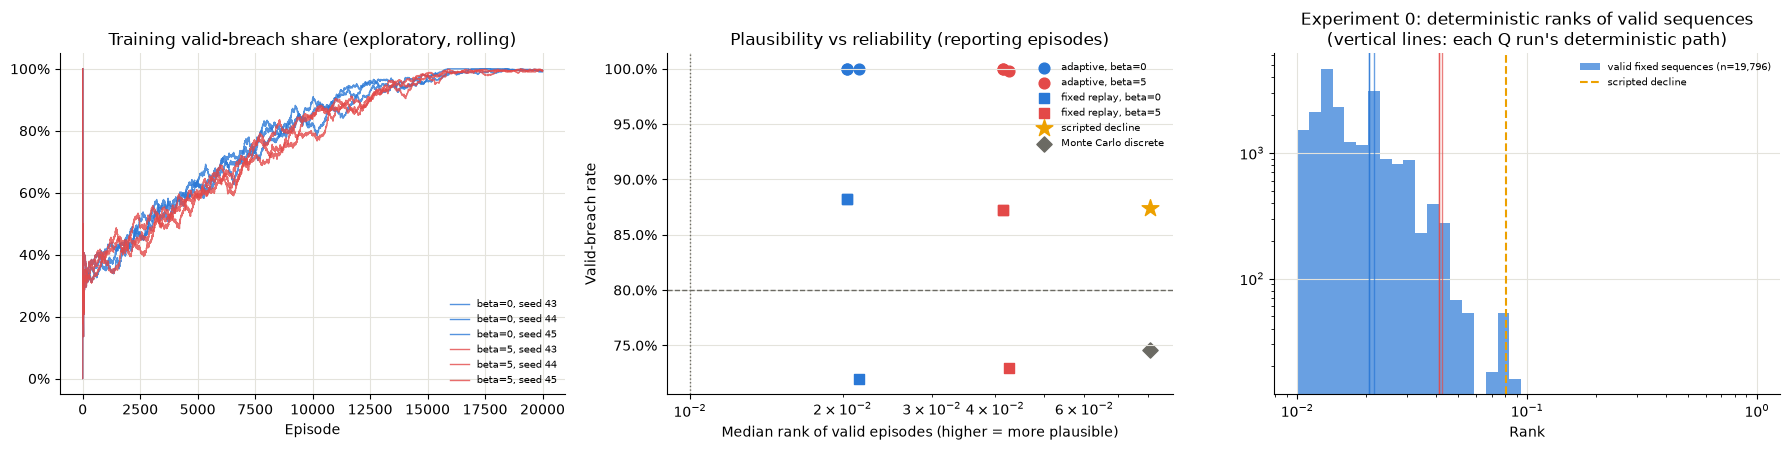

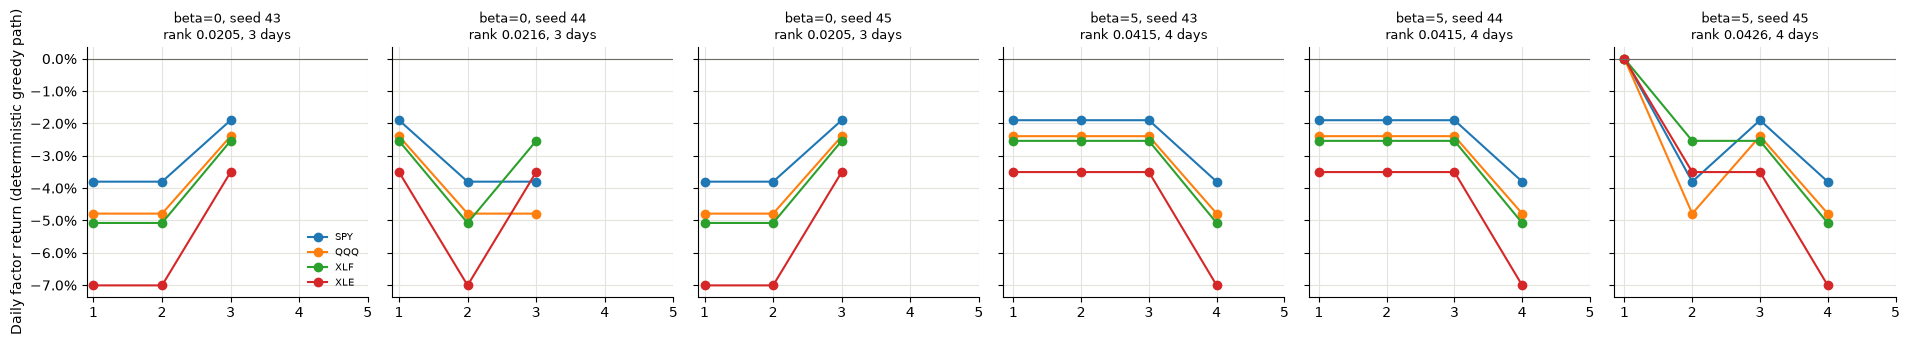

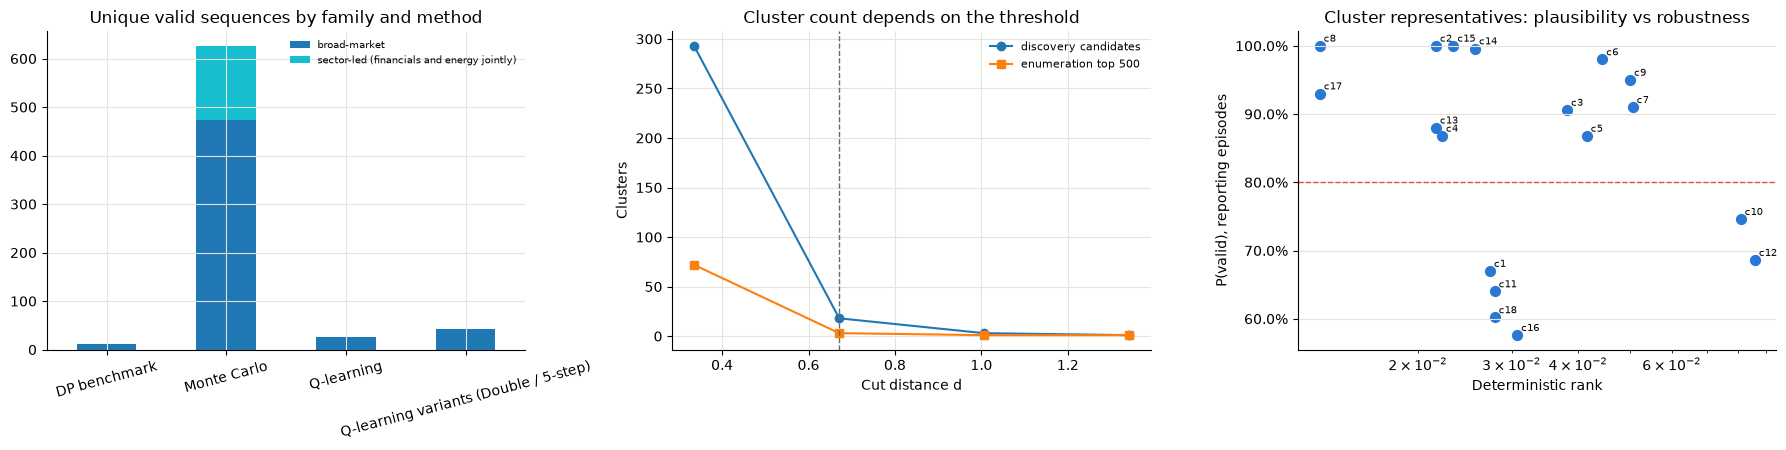

In [20]:
print(BANNER)
colors = {0.0: "#2a78d6", 5.0: "#e34948"}
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
for (beta, seed), r in runs.items():
    roll = r["log"]["valid"].rolling(max(1, len(r["log"]) // 40), min_periods=1).mean() * 100
    axes[0].plot(r["log"]["episode"], roll, color=colors[beta], alpha=0.8, linewidth=1, label=f"beta={beta:g}, seed {seed}")
axes[0].set_title("Training valid-breach share (exploratory, rolling)"); axes[0].set_xlabel("Episode"); axes[0].yaxis.set_major_formatter(PercentFormatter())
axes[0].legend(frameon=False, fontsize=7)
for mode, marker in [("adaptive", "o"), ("fixed replay", "s")]:
    d = q_rows[q_rows["evaluation"] == mode]
    for beta in BETAS:
        e = d[d["beta"] == beta]
        axes[1].scatter(e["median valid rank"], e["valid rate"] * 100, color=colors[beta], marker=marker, s=60, label=f"{mode}, beta={beta:g}")
for name, mk in [("scripted decline (reference)", "*")]:
    row = evals[evals["evaluation"] == name].iloc[0]
    axes[1].scatter(row["median valid rank"], row["valid rate"] * 100, color="#eda100", marker=mk, s=160, label="scripted decline")
axes[1].scatter(mcd_eval["median valid rank"], mcd_eval["valid rate"] * 100, color="#6b6a63", marker="D", s=60, label="Monte Carlo discrete")
axes[1].axhline(P_VALID_TARGET * 100, color="#6b6a63", linestyle="--", linewidth=1); axes[1].axvline(Q_THRESHOLD, color="#6b6a63", linestyle=":", linewidth=1)
axes[1].set_xscale("log"); axes[1].set_xlabel("Median rank of valid episodes (higher = more plausible)"); axes[1].set_ylabel("Valid-breach rate")
axes[1].yaxis.set_major_formatter(PercentFormatter()); axes[1].set_title("Plausibility vs reliability (reporting episodes)"); axes[1].legend(frameon=False, fontsize=7)
if len(valid_enum):
    axes[2].hist(valid_enum["rank"], bins=np.logspace(np.log10(Q_THRESHOLD), 0, 40), color="#2a78d6", alpha=0.7, label=f"valid fixed sequences (n={len(valid_enum):,})")
    axes[2].axvline(scripted_rec["rank"], color="#eda100", linestyle="--", label="scripted decline")
    for (beta, seed), r in runs.items():
        axes[2].axvline(r["det"]["rank"], color=colors[beta], linewidth=1, alpha=0.7)
    axes[2].set_xscale("log"); axes[2].set_yscale("log"); axes[2].legend(frameon=False, fontsize=7)
axes[2].set_title("Experiment 0: deterministic ranks of valid sequences\n(vertical lines: each Q run's deterministic path)"); axes[2].set_xlabel("Rank")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, len(runs), figsize=(3.2 * len(runs), 3.4), sharey=True)
for ax, ((beta, seed), r) in zip(axes, runs.items()):
    fs = np.array(r["det"]["factor_shocks"]) * 100
    for j, n in enumerate(names):
        ax.plot(range(1, r["det"]["days"] + 1), fs[:, j], marker="o", label=n)
    ax.set_title(f"beta={beta:g}, seed {seed}\nrank {r['det']['rank']:.4f}, {r['det']['days']} days", fontsize=9)
    ax.set_xticks(range(1, H + 1)); ax.yaxis.set_major_formatter(PercentFormatter()); ax.axhline(0, color="#6b6a63", linewidth=0.8)
axes[0].set_ylabel("Daily factor return (deterministic greedy path)"); axes[0].legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
if len(fam_tab):
    fam_tab.plot(kind="bar", stacked=True, ax=axes[0], colormap="tab10")
    axes[0].set_title("Unique valid sequences by family and method"); axes[0].set_xlabel(""); axes[0].tick_params(axis="x", rotation=15)
    axes[0].legend(frameon=False, fontsize=7)
axes[1].plot(list(D_GRID), [r["clusters"] for r in sens_rows], marker="o", label="discovery candidates")
axes[1].plot(list(D_GRID), [r[f"enumeration top {len(top_enum)}: clusters"] for r in sens_rows], marker="s", label=f"enumeration top {len(top_enum)}")
axes[1].axvline(D_PRIMARY, color="#6b6a63", linestyle="--", linewidth=1); axes[1].set_xlabel("Cut distance d"); axes[1].set_ylabel("Clusters")
axes[1].set_title("Cluster count depends on the threshold"); axes[1].legend(frameon=False, fontsize=8)
if len(rob_df):
    axes[2].scatter([seen[k]["rec"]["rank"] for k in rob_df["key"]], rob_df["P(valid)"] * 100, s=50, color="#2a78d6")
    for _, r in rob_df.iterrows():
        axes[2].annotate(f"c{r['cluster']}", (seen[r['key']]["rec"]["rank"], r["P(valid)"] * 100), fontsize=7, xytext=(3, 3), textcoords="offset points")
    axes[2].axhline(P_VALID_TARGET * 100, color="#e34948", linestyle="--", linewidth=1); axes[2].set_xscale("log")
    axes[2].set_xlabel("Deterministic rank"); axes[2].set_ylabel("P(valid), reporting episodes"); axes[2].yaxis.set_major_formatter(PercentFormatter())
    axes[2].set_title("Cluster representatives: plausibility vs robustness")
plt.tight_layout(); plt.show()

## 19. Lightweight correctness assertions

In [21]:
checks = []
def check(name, ok, detail=""):
    checks.append({"check": name, "result": "PASS" if ok else "FAIL", "detail": detail})
check("enumeration count == actions^5 and inside bounds", len(enum_df) == len(enum_acts) ** H, f"{len(enum_df):,}")
check("enumeration: valid <=> breached and rank >= q", ((enum_df["valid"]) == (enum_df["breached"] & (enum_df["rank"] >= Q_THRESHOLD))).all())
check("beta = 0 runs never receive a bonus", all((r["log"]["margin_bonus"] == 0).all() for (b, _), r in runs.items() if b == 0.0))
check("bonus only on valid episodes, equal to beta * m(final rank)", all(np.allclose(r["log"]["margin_bonus"],
      [b * plausibility_margin(fr, Q_THRESHOLD) if v else 0.0 for fr, v in zip(r["log"]["final_rank"], r["log"]["valid"])]) for (b, _), r in runs.items()))
check("visits == training steps for every run", all(int(r["agent"].N.sum()) == int(r["log"]["steps"].sum()) for r in runs.values()))
check("greedy policies never pick unvisited actions", all(r["agent"].greedy_action(s) is None or r["agent"].N[s][r["agent"].greedy_action(s)] > 0
                                                          for r in runs.values() for s in np.ndindex(*ENC.shape)))
check("all Q and reference paths inside [-1, 1]", all(np.abs(r["path"]).max() <= 1.0 for r in runs.values()) and np.abs(mcd["selected path"]).max() <= 1.0)
check("same reporting episodes for every arm", evals["episodes"].nunique() == 1 and int(evals["episodes"].iloc[0]) == len(REPORT_SEEDS))
check("discrete MC used >= the Q step budget", mcd["steps"] >= step_budget, f"{mcd['steps']} vs {step_budget}")
check("evaluation anchors are validation dates only", eval_env.market_states.index.max() <= pd.Timestamp(CFG.data.splits.as_dict()["validation"][1])
      and eval_env.market_states.index.min() >= pd.Timestamp(CFG.data.splits.as_dict()["validation"][0]))
check("Stage 4 reward weights unchanged", ENVC.implausible_breach_penalty == 0.0 and ENVC.implausible_breach_credit == 0.0 and ENVC.breach_reward == 10.0)
if RUN_MODE == "full":
    b0 = runs[(0.0, Q_SEEDS[0])]
    check("beta = 0, seed 43 reproduces the v3 run (steps, visited pairs)", int(b0["log"]["steps"].sum()) == 79_738 and int((b0["agent"].N > 0).sum()) == 569,
          f"steps {int(b0['log']['steps'].sum())}, visited {int((b0['agent'].N > 0).sum())}")
check("DP and variants use the same 9 actions and reporting episodes", all(len(v) == len(REPORT_SEEDS) for v in eval_records.values()))
check("candidate pool inside bounds", all(np.abs(v["A"]).max() <= 1.0 for v in seen.values()))
check("families assigned to valid candidates only", all((v["family"] is None) == (not v["rec"]["valid"]) for v in seen.values()))
check("clustering used only valid candidates", set(disc_keys) <= {k for k, v in seen.items() if v["rec"]["valid"]})
check("screening and reporting episodes disjoint", not set(SELECTION_SEEDS) & set(REPORT_SEEDS))
check("library contains only robust clusters", all(c in robust_clusters for c in library["cluster"]) if len(library) else True)
if RUN_MODE == "full":
    b5 = evals[(evals["beta"] == 5.0) & (evals["seed"] == Q_SEEDS[0]) & (evals["evaluation"] == "adaptive")].iloc[0]
    check("v4 results reproduced (enumeration, Q beta=5 seed 43, discrete MC)",
          round(float(enum_best["rank"]), 4) == V4_RECORDED["enum_best_rank"] and round(float(b5["median valid rank"]), 4) == V4_RECORDED["q_beta5_seed43_adaptive_median_rank"]
          and float(b5["valid rate"]) == V4_RECORDED["q_beta5_seed43_adaptive_valid"] and round(float(mcd_eval["valid rate"]), 3) == V4_RECORDED["mcd_reporting_valid"])
checks_df = pd.DataFrame(checks)
display(checks_df.style.hide(axis="index").map(lambda v: "color: #008300; font-weight: bold" if v == "PASS" else ("color: #e34948; font-weight: bold" if v == "FAIL" else ""), subset=["result"]))
assert (checks_df["result"] == "PASS").all()
print(f"{len(checks_df)}/{len(checks_df)} checks PASS")

check,result,detail
enumeration count == actions^5 and inside bounds,PASS,"59,049"
enumeration: valid <=> breached and rank >= q,PASS,
beta = 0 runs never receive a bonus,PASS,
"bonus only on valid episodes, equal to beta * m(final rank)",PASS,
visits == training steps for every run,PASS,
greedy policies never pick unvisited actions,PASS,
"all Q and reference paths inside [-1, 1]",PASS,
same reporting episodes for every arm,PASS,
discrete MC used >= the Q step budget,PASS,79748 vs 79738
evaluation anchors are validation dates only,PASS,


19/19 checks PASS


## 20. Limitations and conclusions
- Evaluation episodes differ only in residual draws: the anchor date does not affect the dynamics and the Q state ignores market state, so "validation" robustness is robustness to stock-specific noise, not to market regimes; nothing here is an out-of-sample test.
- The simulator draws i.i.d. daily shocks (no volatility clustering) with tails about 15–16% lighter than history; plausibility is calibrated on 2015–2021 windows whose most extreme 1% all fall in March–April 2020; the loss limit is never decisive.
- The nine-action set bounds what Q-learning and Experiment 0 can reach; the enumeration is a ceiling only for fixed sequences of these actions.
- β = 5 is one pre-set value, three seeds; the 80% criterion is a proposal, not a standard.
- Diversity: the nine-action set ties SPY to QQQ and XLF to XLE, so several families are structurally unreachable for every discrete method; family rules and the cluster cut are analyst choices (sensitivity shown); the DP benchmark solves an estimated model of a non-Markov binned state.

In [22]:
print(BANNER)
if RUN_MODE != "full":
    print("Conclusions: NOT YET EVALUATED (smoke budgets).")
else:
    print(f"Experiment 0 best valid fixed sequence rank: {enum_best['rank']:.4f}" if enum_best is not None else "Experiment 0: no valid fixed sequence")
    print(agg[[c for c in agg.columns if c.startswith(("valid rate", "median valid rank"))]].to_string())
    print(f"Decision rule met: {criterion_met}")
if RUN_MODE == "full":
    print(learn_agg[[c for c in learn_agg.columns if c.startswith(("valid rate", "median valid rank"))]].to_string())
    print(f"Scenario library: {len(library)} robust scenario(s); families {dict(Counter(library['family'])) if len(library) else {}}")

FULL RUN v4 — authorised experiment
Experiment 0 best valid fixed sequence rank: 0.0859
                   valid rate (mean)  valid rate (std)  median valid rank (mean)  median valid rank (std)
evaluation   beta                                                                                        
adaptive     0.0            1.000000          0.000000                  0.020833                 0.000656
             5.0            0.999333          0.001155                  0.041880                 0.000656
fixed replay 0.0            0.828000          0.093531                  0.020833                 0.000656
             5.0            0.824667          0.081984                  0.041880                 0.000656
Decision rule met: True
                                       valid rate (mean)  valid rate (std)  median valid rank (mean)  median valid rank (std)
method                   evaluation                                                                                          
